# 01 · Find the cloud-free images

**Goal:** choose one Sentinel-2 image from **before** the fire and one from **after**.

**Why:** a burn footprint is a *comparison* of two dates (spot the difference). Both images must be cloud-free **over our area**. The catalogue tells us each image's cloud %, but that number describes a whole 100 × 100 km tile, so a "5 % cloudy" tile can still have its one cloud right on top of our area. That's why we measure the cloud ourselves, inside the AOI only.

**Rules:**
- *Pre-fire:* the clear date closest to ignition − 28 days (vegetation as it was, but not too long before).
- *Post-fire:* the **earliest** clear date after the fire was out (before plants start growing back).

In [1]:
from datetime import date, timedelta
import pandas as pd
import matplotlib.pyplot as plt
from common import *

## 1. Connect to the catalogue
Microsoft Planetary Computer stores every Sentinel-2 image for free. We search it through a **STAC API**, a standard way to ask "which images cover this box between these dates?". The answer is a list of *items*. Each item is one image tile, with links to its bands.

In [2]:
catalog = open_catalog()
fire = date.fromisoformat(CFG["fire_start"])
target = fire - timedelta(days=CFG["days_before"])
print(f"Ignition {fire} → pre-fire target date {target}")

Ignition 2026-07-22 → pre-fire target date 2026-06-24


## 2. The tools: search, then measure real cloud inside the AOI
- `search_by_day` asks the catalogue for images and groups them by date (our area needs **4 tiles** on the same day).
- `score_day` downloads only the small **SCL** layer (Sentinel-2's own pixel classification: cloud, shadow, water…) at a coarse 60 m and counts the cloud pixels **inside the AOI**.
- `rank` scores every date and marks it **CLEAR** if it passes our limits (≤ 1 % cloud, ≥ 99 % data).

In [3]:
def search_by_day(start: str, end: str) -> dict:
    """STAC search -> {date: [items]}."""
    items = catalog.search(collections=[COLLECTION], bbox=CFG["bbox"],
                           datetime=f"{start}/{end}",
                           query={"eo:cloud_cover": {"lt": CFG["max_tile_cloud"]}}).items()
    by_day: dict = {}
    for it in items:
        by_day.setdefault(it.datetime.date().isoformat(), []).append(it)
    return dict(sorted(by_day.items()))


def score_day(items) -> dict:
    """Load only the SCL band at 60 m over the AOI and measure real cloud cover."""
    import odc.stac
    ds = odc.stac.load(items, bands=[QA_BAND], bbox=CFG["bbox"], crs=CFG["crs"],
                       resolution=60, groupby="solar_day", resampling="nearest")
    scl = ds[QA_BAND].isel(time=0).values
    has_data = ~np.isin(scl, SCL_NODATA)
    cover = 100 * has_data.mean()
    cloud = 100 * np.isin(scl[has_data], SCL_CLOUD).mean() if has_data.any() else 100
    return {"coverage_pct": round(float(cover), 2), "aoi_cloud_pct": round(float(cloud), 3)}


def rank(by_day: dict) -> pd.DataFrame:
    rows = []
    for d, items in by_day.items():
        try:
            s = score_day(items)
        except Exception as e:                      # a broken file, network hiccup...
            print(f"   {d}: could not be read ({e})")
            continue
        s.update(date=d, ids=[i.id for i in items],
                 satellite=",".join(sorted({i.properties.get("platform", "?") for i in items})))
        s["clear"] = (s["aoi_cloud_pct"] <= CFG["max_aoi_cloud"]
                      and s["coverage_pct"] >= CFG["min_aoi_coverage"])
        rows.append(s)
    return pd.DataFrame(rows)

## 3. Pre-fire candidates
We search ±7 days around the target. If nothing is clear, the window widens by 7 days at a time, up to ±21. This takes a minute because each date's SCL layer is downloaded.

In [4]:
pre_table, half = None, CFG["pre_window_days"]
while half <= CFG["pre_max_window_days"]:
    start = target - timedelta(days=half)
    end = min(target + timedelta(days=half), fire - timedelta(days=1))
    print(f"Searching {start} → {end} ...")
    pre_table = rank(search_by_day(str(start), str(end)))
    if len(pre_table) and pre_table["clear"].any():
        break
    half += 7
    print(f"   none clear, widening to ±{half} days")

pre_table[["date", "satellite", "aoi_cloud_pct", "coverage_pct", "clear"]]

Searching 2026-06-17 → 2026-07-01 ...


,date,satellite,aoi_cloud_pct,coverage_pct,clear
0,2026-06-19,Sentinel-2B,22.669,100.00,False
1,2026-06-21,Sentinel-2C,0.023,42.95,False
2,2026-06-23,Sentinel-2A,0.788,42.57,False
3,2026-06-24,Sentinel-2C,0.734,100.00,True
4,2026-06-26,"Sentinel-2A,Sentinel-2B",4.426,41.77,False
5,2026-06-29,Sentinel-2B,0.202,100.00,True
6,2026-07-01,Sentinel-2C,0.011,41.98,False


In [5]:
clear = pre_table[pre_table["clear"]].copy()
clear["days_from_target"] = (pd.to_datetime(clear["date"]) - pd.Timestamp(target)).dt.days.abs()
pre = clear.sort_values("days_from_target").iloc[0].to_dict()
print("Chosen pre-fire date:", pre["date"])

Chosen pre-fire date: 2026-06-24


## 4. Post-fire candidates
Here we pick the **earliest** clear date in the window.

In [6]:
post_table = rank(search_by_day(CFG["post_start"], CFG["post_end"]))
post = post_table[post_table["clear"]].sort_values("date").iloc[0].to_dict()
print("Chosen post-fire date:", post["date"])
post_table[["date", "satellite", "aoi_cloud_pct", "coverage_pct", "clear"]]

Chosen post-fire date: 2026-08-08


,date,satellite,aoi_cloud_pct,coverage_pct,clear
0,2026-07-31,Sentinel-2C,0.025,43.44,False
1,2026-08-02,Sentinel-2A,0.015,43.21,False
2,2026-08-03,Sentinel-2C,14.340,99.97,False
3,2026-08-05,"Sentinel-2A,Sentinel-2B",0.193,42.55,False
4,2026-08-08,Sentinel-2B,0.139,99.99,True
5,2026-08-10,Sentinel-2C,0.012,42.74,False
6,2026-08-12,Sentinel-2A,0.014,42.80,False
7,2026-08-13,Sentinel-2C,0.141,99.99,True
8,2026-08-18,Sentinel-2B,0.965,99.99,True
9,2026-08-20,Sentinel-2C,11.489,41.90,False


## 5. Picture it
Each bar is one date. Green = clear enough, grey = too cloudy over our area. The dashed line is the ignition date.

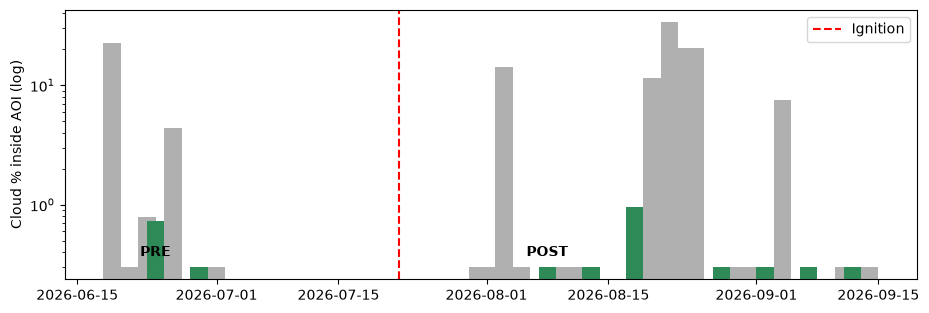

In [7]:
both = pd.concat([pre_table, post_table])
both["d"] = pd.to_datetime(both["date"])
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.bar(both["d"], both["aoi_cloud_pct"].clip(lower=0.3), width=2,
       color=np.where(both["clear"], "#2e8b57", "#b0b0b0"))
ax.axvline(pd.Timestamp(fire), color="red", ls="--", label="Ignition")
for d, lab in ((pre["date"], "PRE"), (post["date"], "POST")):
    ax.annotate(lab, (pd.Timestamp(d), 0.3), xytext=(0, 8), textcoords="offset points",
                ha="center", fontweight="bold")
ax.set_yscale("log"); ax.set_ylabel("Cloud % inside AOI (log)"); ax.legend()
plt.show()

## 6. Save the choice for the next notebook

In [8]:
lag_pre = (fire - date.fromisoformat(pre["date"])).days
lag_post = (date.fromisoformat(post["date"]) - fire).days
for d in (pre, post):
    d.pop("days_from_target", None)
    d["clear"] = bool(d["clear"])
scenes = {"ignition": str(fire), "pre_target": str(target),
          "pre": {**pre, "days_before_ignition": lag_pre},
          "post": {**post, "days_after_ignition": lag_post}}
save_json(scenes, "step1_scenes.json")
print(f"Pre-fire  {pre['date']}  ({lag_pre} days before ignition)")
print(f"Post-fire {post['date']}  ({lag_post} days after ignition)")

Pre-fire  2026-06-24  (28 days before ignition)
Post-fire 2026-08-08  (17 days after ignition)


## What you learned
- A **STAC catalogue** lets you search satellite archives by place and date, without downloading whole images.
- A tile's cloud % can mislead. Measuring cloud **inside your own area** with the SCL layer is more reliable.
- Picking dates is a trade-off: close to the fire (little natural change) but cloud-free.

**Next:** `02_reflectance.ipynb`